In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
np.random.seed(100)
theta = np.random.uniform(0, 2 * np.pi, size=1000)

NameError: name 'x' is not defined

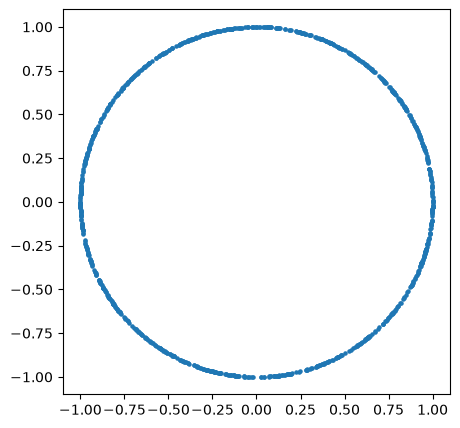

In [ ]:
x = np.cos(theta)
y = np.sin(theta)
plt.figure(figsize=(5, 5))
plt.scatter(x, y, s=5)


In [ ]:
hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

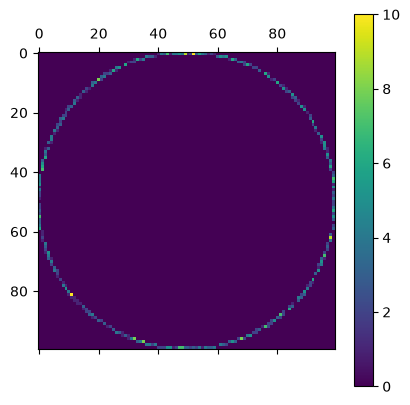

In [ ]:
cs = plt.matshow(hist2d)
plt.colorbar(cs)

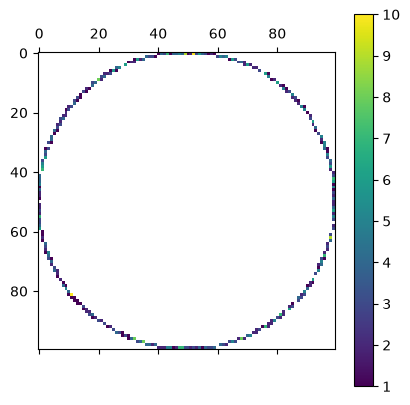

In [ ]:
cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

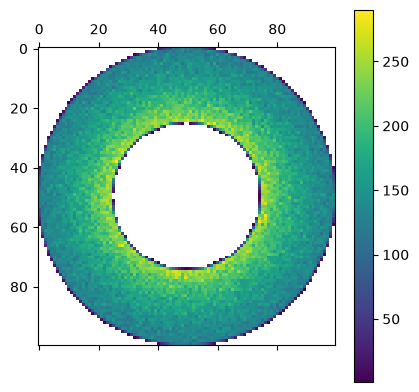

In [ ]:
np.random.seed(1)

theta = np.random.uniform(0, 2 * np.pi, size=1000000)
r = np.random.uniform(1, 2, size=1000000)
x = np.cos(theta) * r
y = np.sin(theta) * r

hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

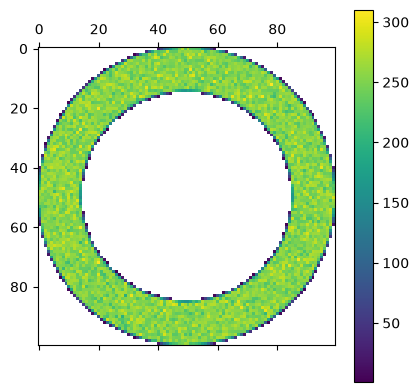

In [ ]:
np.random.seed(1)

theta = np.random.uniform(0, 2 * np.pi, size=1000000)
r = np.sqrt(np.random.uniform(1, 2, size=1000000)) # r^2 should be randomly distributed
x = np.cos(theta) * r
y = np.sin(theta) * r

hist2d, x_edges, y_edges = np.histogram2d(x, y, bins=100)

cs = plt.matshow(np.ma.array(hist2d, mask=hist2d==0.0))
plt.colorbar(cs)

In [ ]:
df = pd.DataFrame.from_records(np.vstack((x, y, r)).T,columns=["x", "y", "p"])

In [ ]:
df.head()
df.tail()

,x,y,p
999995,1.141718,0.368102,1.199591
999996,-1.171174,0.585723,1.309473
999997,-1.113241,0.047356,1.114248
999998,1.065070,0.867768,1.373825
999999,-0.779769,0.827741,1.137187


In [ ]:
df.mean()

x   -0.000571
y   -0.000674
p    1.218840
dtype: float64

In [ ]:
df["x"].std() # без смещения

np.float64(0.8651476129509048)

In [ ]:
df.max(), df.min()

(x    1.414193
 y    1.414050
 p    1.414213
 dtype: float64,
 x   -1.414085
 y   -1.414119
 p    1.000001
 dtype: float64)

In [ ]:
(((df["x"] - df["x"].mean())**2).sum() / (df["x"].size))**0.5

np.float64(0.8651471803769901)

In [ ]:
print(df["x"].loc[100])
df.loc[100]

-0.57426251016851


x   -0.574263
y    1.098829
p    1.239840
Name: 100, dtype: float64

In [ ]:
df.index = [f"particle_{idx:06d}" for idx in range(df["x"].size)]
df

,x,y,p
particle_000000,-0.925160,0.531391,1.066910
particle_000001,-0.241239,-1.278780,1.301335
particle_000002,1.247851,0.000897,1.247851
particle_000003,-0.351337,1.029706,1.087994
particle_000004,0.653160,0.861508,1.081117
...,...,...,...
particle_999995,1.141718,0.368102,1.199591
particle_999996,-1.171174,0.585723,1.309473
particle_999997,-1.113241,0.047356,1.114248
particle_999998,1.065070,0.867768,1.373825


In [ ]:
df.loc["particle_001000"]

x   -0.553567
y    1.072902
p    1.207292
Name: particle_001000, dtype: float64

In [ ]:
df.iloc[1000]

x   -0.553567
y    1.072902
p    1.207292
Name: particle_1000, dtype: float64

In [ ]:
df.loc["particle_001000":"particle_002000":2]

,x,y,p
particle_001000,-0.553567,1.072902,1.207292
particle_001002,0.012939,-1.205787,1.205857
particle_001004,-1.013863,0.196846,1.032795
particle_001006,1.068910,0.285035,1.106261
particle_001008,1.345582,0.319584,1.383013
...,...,...,...
particle_001992,-1.100507,-0.450074,1.188983
particle_001994,0.318966,-1.060748,1.107667
particle_001996,0.421774,0.960188,1.048739
particle_001998,1.256931,0.247951,1.281154


In [ ]:
tg_theta = df["y"] / df["x"]
tg_theta

particle_000000   -0.574377
particle_000001    5.300879
particle_000002    0.000719
particle_000003   -2.930818
particle_000004    1.318986
                     ...   
particle_999995    0.322410
particle_999996   -0.500116
particle_999997   -0.042539
particle_999998    0.814752
particle_999999   -1.061521
Length: 1000000, dtype: float64

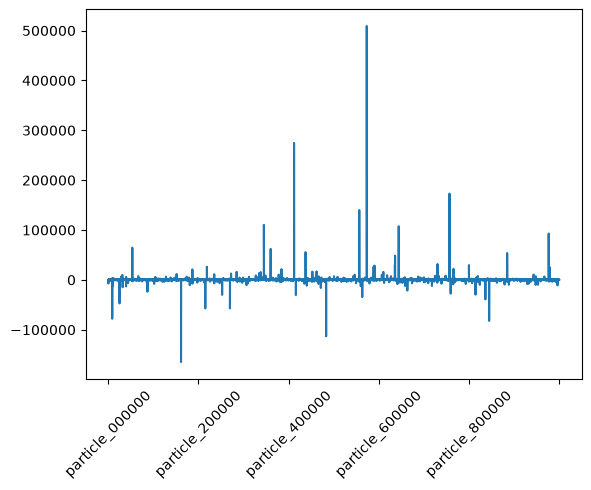

In [ ]:
tg_theta.plot()
plt.xticks(rotation=45);

In [ ]:
# преобразование фурье ???

<Axes: ylabel='Frequency'>

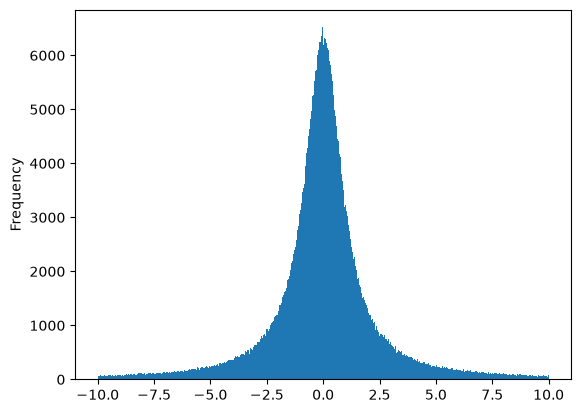

In [ ]:
tg_theta[(tg_theta < 10) & (tg_theta > -10)].plot(kind="hist", bins=1000)

In [ ]:
df_shorten = df[(tg_theta > 2.5) & (tg_theta < 5.0)]
df_shorten["energy_category"] = df_shorten["p"].apply(
    lambda p: "high" if p > 1.35 else "low" if p < 1.1 else "medium"
)
df_shorten.head(10)

,x,y,p,energy_category
particle_000012,0.343733,1.168115,1.217639,medium
particle_000019,0.369944,1.093992,1.154849,medium
particle_000023,-0.488257,-1.287791,1.377243,high
particle_000034,-0.371931,-0.972756,1.041435,low
particle_000052,0.325227,1.322705,1.362102,high
particle_000059,-0.410891,-1.258090,1.323489,medium
particle_000062,-0.446074,-1.224519,1.303238,medium
particle_000108,-0.363765,-0.934111,1.002441,low
particle_000113,-0.340318,-0.980265,1.037659,low
particle_000118,-0.313507,-1.271477,1.309558,medium


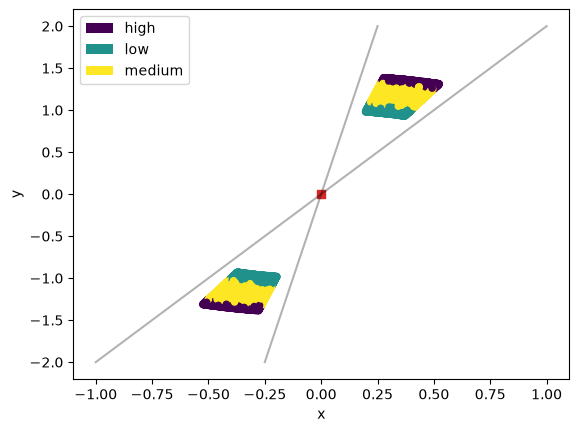

In [ ]:
df_shorten.plot.scatter(x="x", y="y", c="energy_category")
plt.plot([-1, 1], [-2, 2], color="black", alpha=0.3);
plt.plot([-0.25, 0.25], [-2, 2], color="black", alpha=0.3);
plt.scatter(0, 0, marker="s", color="C3")

<Axes: xlabel='x', ylabel='y'>

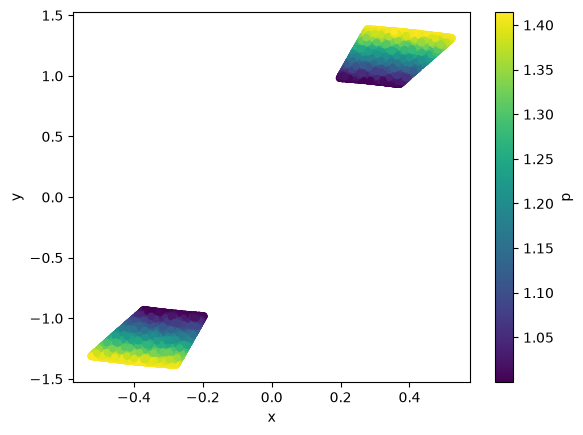

In [ ]:
df_shorten.plot.scatter(x="x", y="y", c="p")

In [ ]:
df_shorten.describe()
# проценты - квантиль

,x,y,p
count,59021.000000,59021.000000,59021.000000
mean,-0.000632,-0.002624,1.219890
std,0.354428,1.173340,0.119149
min,-0.524012,-1.386527,1.000011
25%,-0.344212,-1.174273,1.118771
50%,-0.204598,-0.940152,1.226354
75%,0.343888,1.172780,1.324136
max,0.523198,1.385511,1.414212


In [ ]:
df_shorten.groupby(by=["energy_category"]).agg({"x": "mean", "y": "min", "p": sum}).reset_index()
# в рамках каждой категории подсчитана соотв функция для каждого столба (среднее иксов, min игреков и сумма импульсов)

,energy_category,x,y,p
0,high,0.000264,-1.386527,14605.247971
1,low,0.000078,-1.077851,12924.102539
2,medium,-0.001135,-1.322978,44469.785848


In [ ]:
df_shorten.info()

<class 'pandas.DataFrame'>
Index: 59021 entries, particle_000012 to particle_999972
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   x                59021 non-null  float64
 1   y                59021 non-null  float64
 2   p                59021 non-null  float64
 3   energy_category  59021 non-null  str    
dtypes: float64(3), str(1)
memory usage: 4.3+ MB


In [2]:
df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab08/telecom_churn.csv")
df.to_excel("table.xlsx")
# df.to_csv("local.csv")
df

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,AZ,192,415,No,Yes,36,156.2,77,26.55,215.5,126,18.32,279.1,83,12.56,9.9,6,2.67,2,False
3329,WV,68,415,No,No,0,231.1,57,39.29,153.4,55,13.04,191.3,123,8.61,9.6,4,2.59,3,False
3330,RI,28,510,No,No,0,180.8,109,30.74,288.8,58,24.55,191.9,91,8.64,14.1,6,3.81,2,False
3331,CT,184,510,Yes,No,0,213.8,105,36.35,159.6,84,13.57,139.2,137,6.26,5.0,10,1.35,2,False


In [ ]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
df.to_dict(orient="list")

{'State': ['KS',
  'OH',
  'NJ',
  'OH',
  'OK',
  'AL',
  'MA',
  'MO',
  'LA',
  'WV',
  'IN',
  'RI',
  'IA',
  'MT',
  'IA',
  'NY',
  'ID',
  'VT',
  'VA',
  'TX',
  'FL',
  'CO',
  'AZ',
  'SC',
  'VA',
  'NE',
  'WY',
  'MT',
  'MO',
  'HI',
  'IL',
  'NH',
  'LA',
  'AZ',
  'OK',
  'GA',
  'AK',
  'MA',
  'AK',
  'NJ',
  'GA',
  'MD',
  'AR',
  'ID',
  'WI',
  'OR',
  'MI',
  'DE',
  'ID',
  'WY',
  'IA',
  'IN',
  'VA',
  'UT',
  'WY',
  'IN',
  'CO',
  'CO',
  'WI',
  'OK',
  'ID',
  'CA',
  'MN',
  'SD',
  'NC',
  'WA',
  'WY',
  'MN',
  'UT',
  'TX',
  'NJ',
  'MN',
  'NM',
  'NV',
  'HI',
  'MN',
  'DC',
  'NY',
  'MN',
  'MD',
  'WV',
  'OR',
  'CO',
  'GA',
  'TX',
  'VT',
  'IN',
  'WV',
  'KY',
  'NJ',
  'DC',
  'LA',
  'AR',
  'ME',
  'AZ',
  'AK',
  'MT',
  'AZ',
  'MS',
  'ID',
  'IA',
  'MA',
  'VT',
  'KY',
  'IN',
  'AZ',
  'MI',
  'NM',
  'CO',
  'UT',
  'MI',
  'MA',
  'AL',
  'DE',
  'AZ',
  'ME',
  'NJ',
  'NV',
  'MO',
  'ID',
  'NE',
  'TX',
  'MD',
  'MS',

In [ ]:
df.to_dict(orient="index")

{0: {'State': 'KS',
  'Account length': 128,
  'Area code': 415,
  'International plan': 'No',
  'Voice mail plan': 'Yes',
  'Number vmail messages': 25,
  'Total day minutes': 265.1,
  'Total day calls': 110,
  'Total day charge': 45.07,
  'Total eve minutes': 197.4,
  'Total eve calls': 99,
  'Total eve charge': 16.78,
  'Total night minutes': 244.7,
  'Total night calls': 91,
  'Total night charge': 11.01,
  'Total intl minutes': 10.0,
  'Total intl calls': 3,
  'Total intl charge': 2.7,
  'Customer service calls': 1,
  'Churn': False},
 1: {'State': 'OH',
  'Account length': 107,
  'Area code': 415,
  'International plan': 'No',
  'Voice mail plan': 'Yes',
  'Number vmail messages': 26,
  'Total day minutes': 161.6,
  'Total day calls': 123,
  'Total day charge': 27.47,
  'Total eve minutes': 195.5,
  'Total eve calls': 103,
  'Total eve charge': 16.62,
  'Total night minutes': 254.4,
  'Total night calls': 103,
  'Total night charge': 11.45,
  'Total intl minutes': 13.7,
  'Total 

In [ ]:
import ROOT

In [6]:
df.to_hdf("table.hdf5",key="table")

In [7]:
import seaborn as sns

In [13]:
df = sns.load_dataset("penguins")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


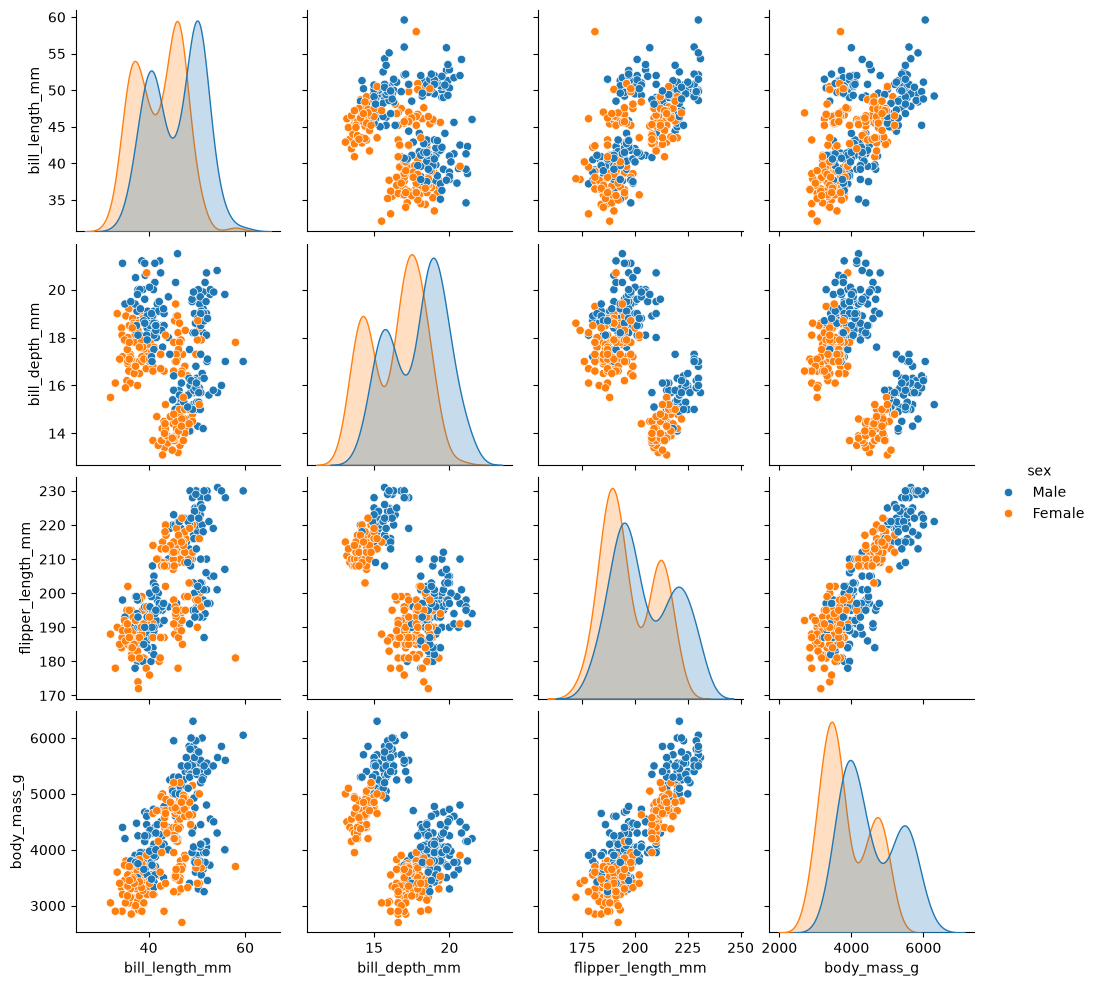

In [ ]:
sns.pairplot(df, hue="sex")

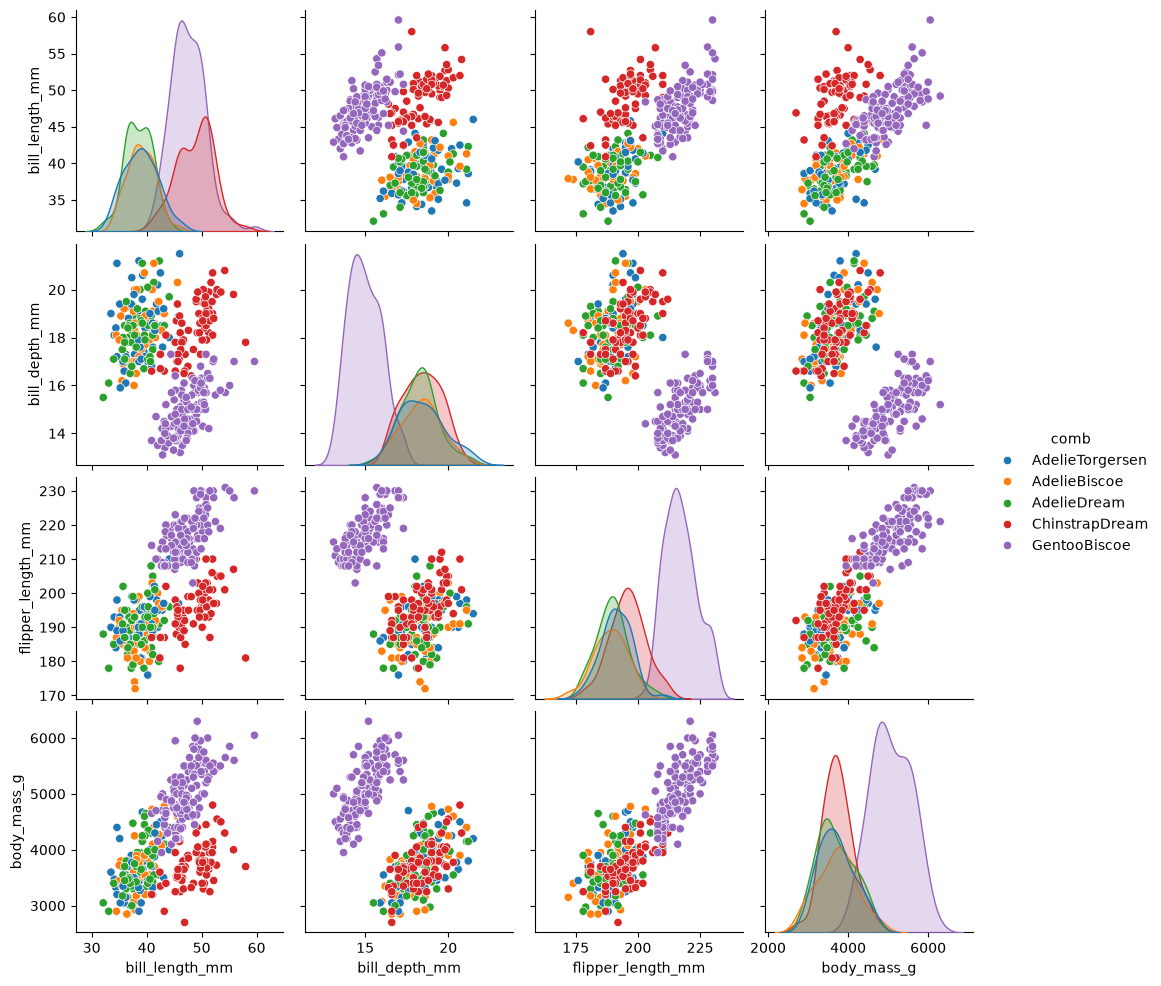

In [ ]:
df["comb"] = df["species"] + df["island"]
sns.pairplot(df, hue="comb")

In [23]:
df.dropna()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,sps,omb,comb
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,AdelieMale,AdelieTorgersen,AdelieTorgersen
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,AdelieMale,AdelieTorgersen,AdelieTorgersen
...,...,...,...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female,GentooFemale,GentooBiscoe,GentooBiscoe
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female,GentooFemale,GentooBiscoe,GentooBiscoe
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male,GentooMale,GentooBiscoe,GentooBiscoe
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female,GentooFemale,GentooBiscoe,GentooBiscoe


In [28]:
n = df[df.sex.isna()].shape[0]
df[df.sex.isna()]["sex"] = np.random.choice(["Male", "Female"], n)


/tmp/ipykernel_498025/3820116763.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  df[df.sex.isna()]["sex"] = np.random.choice(["Male", "Female"], n)


In [31]:
df.loc[df.sex.isna(), "sex"] = np.random.choice(["Male", "Female"], n)

In [33]:
df["sex"]

0        Male
1      Female
2      Female
3        Male
4      Female
        ...  
339      Male
340    Female
341      Male
342    Female
343      Male
Name: sex, Length: 344, dtype: str

In [34]:
df.drop_duplicates()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,sps,omb,comb
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,AdelieMale,AdelieTorgersen,AdelieTorgersen
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,Male,NaN,AdelieTorgersen,AdelieTorgersen
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,AdelieFemale,AdelieTorgersen,AdelieTorgersen
...,...,...,...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,Male,NaN,GentooBiscoe,GentooBiscoe
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female,GentooFemale,GentooBiscoe,GentooBiscoe
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male,GentooMale,GentooBiscoe,GentooBiscoe
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female,GentooFemale,GentooBiscoe,GentooBiscoe


In [ ]:
df.loc[df["bill_depth_mm"].isnull()]
bill_mean = df.groupby(by=["species", "island", "sex"]).agg({"bill_length_mm": "mean"})

print(bill_mean)
for idx_spec, val in bill_mean.iterrows():
    print(val.bill_length_mm)
    # df.loc[(df[["species", "island", "sex"]] == idx_spec) & df["bill_length_mm"].isnull(), "bill_length_mm"] = val.bill_length_mm

    # df.loc[(df["species"] == idx_spec[0]) & df["bill_length_mm"].isnull(), "bill_length_mm"] = val.bill_length_mm

                            bill_length_mm
species   island    sex                   
Adelie    Biscoe    Female       37.359091
                    Male         40.590909
          Dream     Female       36.932143
                    Male         40.071429
          Torgersen Female       37.444444
                    Male         40.514364
Chinstrap Dream     Female       46.573529
                    Male         51.094118
Gentoo    Biscoe    Female       45.545763
                    Male         49.253012
37.35909090909091


/tmp/ipykernel_498025/586876531.py:7: Pandas4Warning: Operation with tuple is deprecated. In a future version these will be treated as scalar-like. To retain the old behavior, explicitly wrap in a Series instead.
  df.loc[(df[["species", "island", "sex"]] == idx_spec) & df["bill_length_mm"].isnull(), "bill_length_mm"] = val.bill_length_mm


TypeError: 'int' object is not iterable

In [ ]:
bill_mean = 
df_copy = df.copy()

for idx_species, val in bill_mean.iterrows():
    idx = df_copy[df_copy.species == idx_species].loc[df["bill_length_mm"].isnull()].index
    df_copy.loc[idx, ["bill_length_mm", "bill_depth_mm"]] = val

df_copy

In [73]:
# df[["species", "body_mass_g"]].apply(lambda x: str(x[1]))
df.groupby(by=["species", "body_mass_g"]).apply(lambda x: x["island"])


species  body_mass_g     
Adelie   2850.0       58        Biscoe
                      64        Biscoe
         2900.0       54        Biscoe
                      98         Dream
                      116    Torgersen
                               ...    
Gentoo   5950.0       331       Biscoe
         6000.0       297       Biscoe
                      337       Biscoe
         6050.0       253       Biscoe
         6300.0       237       Biscoe
Name: island, Length: 342, dtype: str

<Axes: >

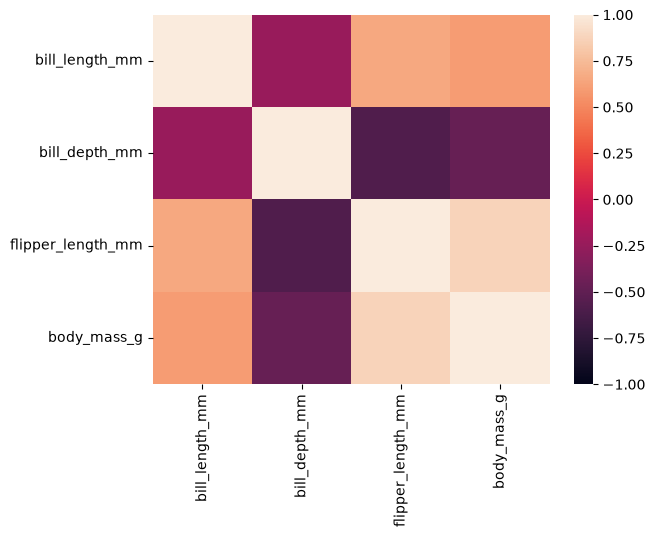

In [74]:
df = sns.load_dataset("penguins")
sns.heatmap(df.select_dtypes("<f8").corr(), vmin=-1, vmax=1)

In [88]:
df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab09/Titanic.csv")
answer = df.groupby(by=["Gender"]).min()
print(answer)

        PassengerId  Survived  Pclass                           Name   Age  \
Gender                                                                       
female          893         1       1    Abelseth, Miss. Karen Marie  0.17   
male            892         0       1  Abbott, Master. Eugene Joseph  0.33   

        SibSp  Parch  Ticket  Fare Cabin Embarked  
Gender                                             
female      0      0  112377  6.95   A11        C  
male        0      0  110469  0.00   A18        C  


In [92]:
df.sort_values(by=["Age", "Gender"])["Name"].head(2)

354    Dean, Miss. Elizabeth Gladys Millvina""
201    Danbom, Master. Gilbert Sigvard Emanuel
Name: Name, dtype: str

In [93]:
df.head()

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [ ]:
n = df.shape[0]
print(n)
df.groupby(by="Pclass").agg({"Age": "mean"})

418


,Age
Pclass,
1,40.918367
2,28.777500
3,24.027945


In [111]:
answer = pd.DataFrame(df['Pclass'].value_counts())
answer["count"] /= n
answer = answer.rename(columns={"count": "Passenger share"}).sort_values("Pclass")
print(answer)


        Passenger share
Pclass                 
1              0.255981
2              0.222488
3              0.521531


In [116]:
# df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab09/Titanic.csv")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

unique_counts = df.nunique()
max_unique = unique_counts.max()

cols_to_drop = unique_counts[unique_counts == max_unique].index
df.drop(columns=cols_to_drop, inplace=True)

answer = df
print(answer)

     Survived  Pclass  Gender    Age  SibSp  Parch              Ticket  \
0           0       3    male  34.50      0      0              330911   
1           1       3  female  47.00      1      0              363272   
2           0       2    male  62.00      0      0              240276   
3           0       3    male  27.00      0      0              315154   
4           1       3  female  22.00      1      1             3101298   
5           0       3    male  14.00      0      0                7538   
6           1       3  female  30.00      0      0              330972   
7           0       2    male  26.00      1      1              248738   
8           1       3  female  18.00      0      0                2657   
9           0       3    male  21.00      2      0           A/4 48871   
10          0       3    male    NaN      0      0              349220   
11          0       1    male  46.00      0      0                 694   
12          1       1  female  23.00  

/tmp/ipykernel_498025/2959741575.py:10: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=cols_to_drop, inplace=True)


In [140]:
df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab09/Titanic.csv")

ans = df.groupby("Gender").agg({"Survived": "mean"})

p = pd.DataFrame({"Survived": {"all": df["Survived"].mean()}})

p.index.name = "Gender"
print(pd.concat([ans, p]))

        Survived
Gender          
female  1.000000
male    0.000000
all     0.363636


In [130]:
ans

,Survived,all
Gender,,
female,1.0,1
male,0.0,1


In [ ]:
df = pd.read_csv("http://python.mipt.ru/lpr/extra/lab09/Titanic.csv")

answer = df.groupby("Pclass").agg({"Survived": "mean"})

        Survived
Pclass          
1       0.467290
2       0.322581
3       0.330275


In [146]:
df["Age group"] = df.loc[~df["Age"].isnull(), "Age"].apply(
    lambda p: "60+" if p > 60 else "18-60" if p >= 18 else "18-"
)

In [147]:
answer = df.groupby("Age group").agg({"Survived": "mean"})

answer

,Survived
Age group,
18-,0.414634
18-60,0.378571
60+,0.363636
